# Sod shock tube against the exact solution

A 1D Sod shock tube run through `luna.launch`, the same path as `python main.py`
(`launch(cfg)` = JAX start-up + `luna.main.run(cfg)`). The `Config` below is what a run
file would hold; `python main.py my_run.py Nx=256 t_end=0.2` runs the same problem from the
command line. The final state is compared with the exact Riemann solution
(`luna.hydro.exact_riemann`), averaged over each cell.

The simulation itself takes a few seconds on a CPU (6.4 s on four cores of a loaded login node, as
recorded below); importing JAX and compiling add to that.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # this notebook is sized for a CPU; unset it to use a GPU

from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from luna import Config, launch

In [2]:
cfg = replace(Config(),
              test_problem="Sod-Shock", SPATIAL_DIMENSION=1, Nx=256, t_end=0.2,
              time_bet_snaps=0.05, PLOT_AFTER_SIM=False, output_cadence=1000, diag_interval=1000,
              output_dir="snapshots/nb_sod", clear_output_dir=True)
res = launch(cfg)
print("t =", res.t, " steps =", res.n_steps, " output:", res.output_dir)

MULTI-NODE SHARDING MODE (1 GPU per process)
  Running in single-process mode (use SLURM/MPI for multi-node)
Platform: cpu
Total devices: 1
Local devices: 1
  Device 0: cpu (process 0)



DOMAIN DECOMPOSITION (1 devices)
Decomposition strategy: auto
Process grid: (1,)
Actual decomposition: slab (1D)

INITIAL CONDITIONS
Single-process mode: generating global initial conditions...


Global shape: (3, 256)
Validating initial conditions...


✓ Initial conditions validated successfully

Sharding global array to all devices...
✓ Array sharded across 1 devices
  Each process keeps only its local shard

After initialization: Memory usage: 0.26 GB

Using shard_map with explicit per-shard ppermute halos
Sharding spec: P(None, 'x')
Using MUSCL-Hancock (HLLC, shard_map) time integration
Runner controls dt clamping (snapshot times, t_end)


✓ Compilation complete (0.9s)



SIMULATION START
t=0.00000e+00 -> t=2.00000e-01
Global grid: 256 x 1024 x 1024



... (5 outputs left out)


────────────────────────────────────────────────────────────
💾 Saving snapshot #3 at t=1.50000e-01
────────────────────────────────────────────────────────────
Process 0 shard 0: saved snap_003.0.hdf5
✓ snapshot written




────────────────────────────────────────────────────────────
💾 Saving snapshot #4 at t=2.00000e-01
────────────────────────────────────────────────────────────
Process 0 shard 0: saved snap_004.0.hdf5
✓ snapshot written



[gas] done: 147 steps, t=2.00000e-01, 6.4s



SIMULATION COMPLETED
✓ Total runtime: 6.37 seconds
✓ Total steps: 147
✓ Final time: 0.20000
✓ Average performance: 0.01 Mcells/s (global grid)
✓ Time per step: 43.61 ms (excluding first step)

Number of devices: 1
Process grid: (1,)

Final memory usage: Memory usage: 0.30 GB

Good Bye and Good Day!
t = 0.2  steps = 147  output: snapshots/nb_sod


`res.extra["U"]` is the final conserved state `[rho, rho*u, E]` (1D). Defaults on `main`:
FP32 (`enable_x64=False`), PLM with the minmod limiter, HLLC, CFL 0.8, the XLA kernel.

In [3]:
from luna.hydro import exact_riemann

U = np.asarray(res.extra["U"], dtype=np.float64)
g = cfg.gamma
rho, u = U[0], U[1] / U[0]
p = (g - 1.0) * (U[2] - 0.5 * U[0] * u * u)

edges = np.linspace(0.0, cfg.Lx, cfg.Nx + 1)
x = 0.5 * (edges[:-1] + edges[1:])
# Sod states (luna/ic_generation/sod.py): left (rho, u, p) = (1, 0, 1), right (0.125, 0, 0.1), jump at Lx/2
rho_e, u_e, p_e = exact_riemann.cell_average((1.0, 0.0, 1.0), (0.125, 0.0, 0.1), g,
                                             edges, 0.5 * cfg.Lx, res.t)
print(f"L1(rho) = {np.mean(np.abs(rho - rho_e)):.3e}  at Nx = {cfg.Nx}")

L1(rho) = 3.210e-03  at Nx = 256


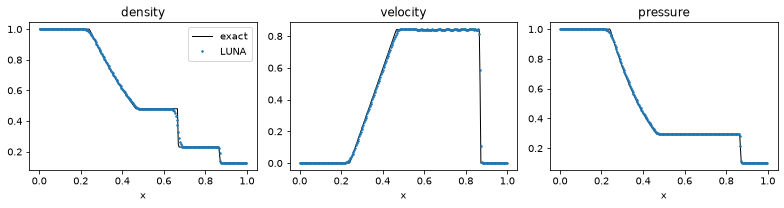

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3), dpi=72)
for a, f, e, name in zip(ax, (rho, u, p), (rho_e, u_e, p_e), ("density", "velocity", "pressure")):
    a.plot(x, e, "k-", lw=1, label="exact")
    a.plot(x, f, ".", ms=3, label="LUNA")
    a.set_xlabel("x"); a.set_title(name)
ax[0].legend()
fig.tight_layout()